# ***Importing Libraries***

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import warnings
warnings.filterwarnings('ignore')

SEED = 42
keras.utils.set_random_seed(SEED)

# ***Exploratory Data Analysis (EDA)***

In [2]:
(X_train_full, y_train_full), (X_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [3]:
print(X_train_full.shape, y_train_full.shape)
print(X_test.shape, y_test.shape)

(60000, 28, 28) (60000,)
(10000, 28, 28) (10000,)


In [4]:
print(X_train_full.min(), X_train_full.max())

0 255


In [5]:
pd.Series(y_train_full).map(dict(enumerate(class_names))).value_counts()

,count
Ankle boot,6000
T-shirt/top,6000
Dress,6000
Pullover,6000
Sneaker,6000
Sandal,6000
Trouser,6000
Shirt,6000
Coat,6000
Bag,6000


# ***Data Visualization***

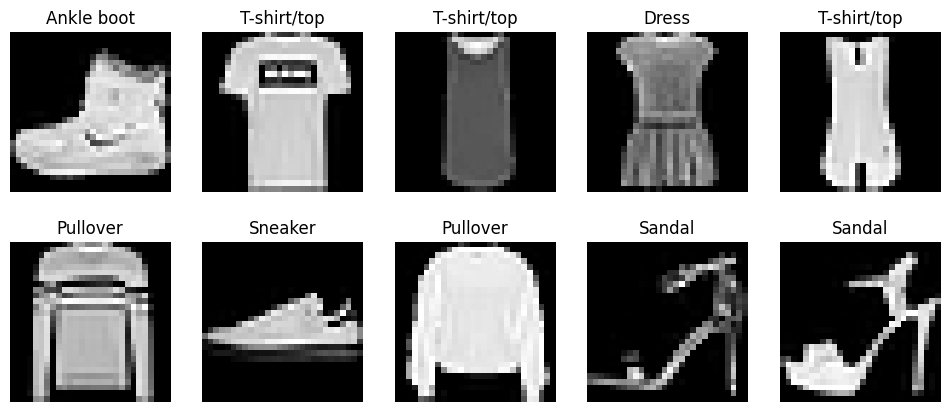

In [6]:
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train_full[i], cmap='gray')
    plt.title(class_names[y_train_full[i]])
    plt.axis('off')
plt.show()

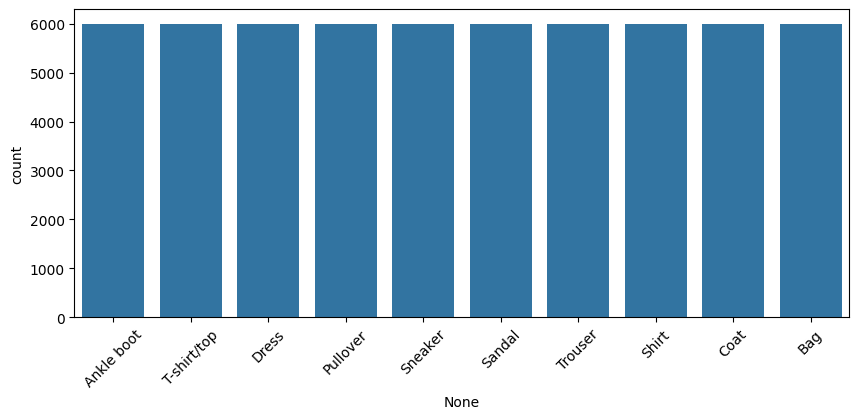

In [7]:
plt.figure(figsize=(10, 4))
sns.countplot(x=pd.Series(y_train_full).map(dict(enumerate(class_names))))
plt.xticks(rotation=45)
plt.show()

# ***Data Preprocessing***

In [8]:
X_train_full = X_train_full.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

X_train_full = X_train_full.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

In [9]:
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.1, stratify=y_train_full, random_state=SEED)
print(X_train.shape, X_val.shape, X_test.shape)

(54000, 28, 28, 1) (6000, 28, 28, 1) (10000, 28, 28, 1)


# ***ANN Model***

In [10]:
ann_model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(10, activation='softmax')
])

ann_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
ann_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

ann_history = ann_model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=30, batch_size=128, callbacks=[early_stop], verbose=2)

Epoch 1/30
422/422 - 7s - 18ms/step - accuracy: 0.7718 - loss: 0.6417 - val_accuracy: 0.8493 - val_loss: 0.4116
Epoch 2/30
422/422 - 1s - 3ms/step - accuracy: 0.8403 - loss: 0.4420 - val_accuracy: 0.8692 - val_loss: 0.3609
Epoch 3/30
422/422 - 2s - 4ms/step - accuracy: 0.8541 - loss: 0.4036 - val_accuracy: 0.8802 - val_loss: 0.3350
Epoch 4/30
422/422 - 1s - 3ms/step - accuracy: 0.8639 - loss: 0.3769 - val_accuracy: 0.8813 - val_loss: 0.3177
Epoch 5/30
422/422 - 1s - 3ms/step - accuracy: 0.8675 - loss: 0.3604 - val_accuracy: 0.8863 - val_loss: 0.3115
Epoch 6/30
422/422 - 1s - 3ms/step - accuracy: 0.8733 - loss: 0.3444 - val_accuracy: 0.8883 - val_loss: 0.3031
Epoch 7/30
422/422 - 1s - 3ms/step - accuracy: 0.8772 - loss: 0.3312 - val_accuracy: 0.8898 - val_loss: 0.2993
Epoch 8/30
422/422 - 1s - 3ms/step - accuracy: 0.8800 - loss: 0.3233 - val_accuracy: 0.8892 - val_loss: 0.2958
Epoch 9/30
422/422 - 1s - 3ms/step - accuracy: 0.8845 - loss: 0.3140 - val_accuracy: 0.8912 - val_loss: 0.2912


# ***CNN Model***

In [12]:
cnn_model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(10, activation='softmax')
])

cnn_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

cnn_history = cnn_model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=30, batch_size=128, callbacks=[early_stop], verbose=2)

Epoch 1/30
422/422 - 13s - 30ms/step - accuracy: 0.7764 - loss: 0.6132 - val_accuracy: 0.8583 - val_loss: 0.3972
Epoch 2/30
422/422 - 2s - 5ms/step - accuracy: 0.8568 - loss: 0.3971 - val_accuracy: 0.8838 - val_loss: 0.3196
Epoch 3/30
422/422 - 2s - 5ms/step - accuracy: 0.8735 - loss: 0.3437 - val_accuracy: 0.8908 - val_loss: 0.2934
Epoch 4/30
422/422 - 2s - 5ms/step - accuracy: 0.8864 - loss: 0.3109 - val_accuracy: 0.9007 - val_loss: 0.2689
Epoch 5/30
422/422 - 2s - 5ms/step - accuracy: 0.8953 - loss: 0.2863 - val_accuracy: 0.9043 - val_loss: 0.2590
Epoch 6/30
422/422 - 2s - 6ms/step - accuracy: 0.9023 - loss: 0.2650 - val_accuracy: 0.9097 - val_loss: 0.2476
Epoch 7/30
422/422 - 2s - 5ms/step - accuracy: 0.9093 - loss: 0.2480 - val_accuracy: 0.9125 - val_loss: 0.2398
Epoch 8/30
422/422 - 2s - 5ms/step - accuracy: 0.9131 - loss: 0.2340 - val_accuracy: 0.9137 - val_loss: 0.2368
Epoch 9/30
422/422 - 2s - 5ms/step - accuracy: 0.9187 - loss: 0.2205 - val_accuracy: 0.9158 - val_loss: 0.2350

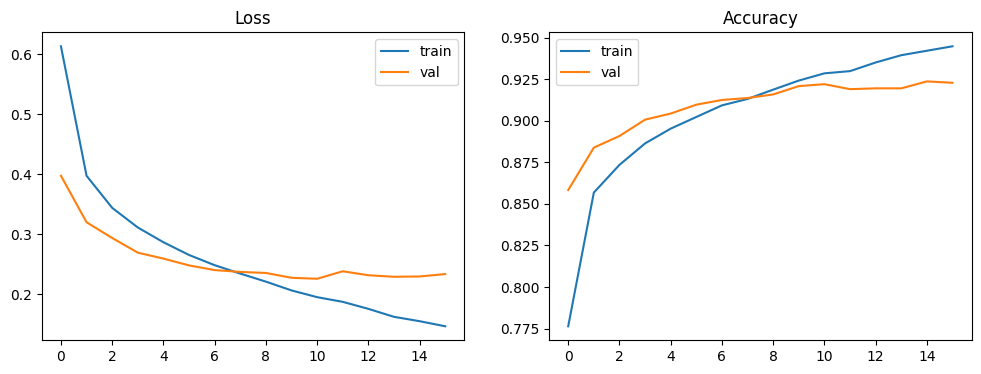

In [14]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(cnn_history.history['loss'], label='train')
plt.plot(cnn_history.history['val_loss'], label='val')
plt.title('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(cnn_history.history['accuracy'], label='train')
plt.plot(cnn_history.history['val_accuracy'], label='val')
plt.title('Accuracy')
plt.legend()

plt.show()

# ***Evaluating the CNN***

In [15]:
y_pred_cnn = np.argmax(cnn_model.predict(X_test, verbose=0), axis=1)
print(classification_report(y_test, y_pred_cnn, target_names=class_names))

              precision    recall  f1-score   support

 T-shirt/top       0.86      0.85      0.86      1000
     Trouser       1.00      0.97      0.98      1000
    Pullover       0.86      0.87      0.86      1000
       Dress       0.90      0.92      0.91      1000
        Coat       0.88      0.83      0.85      1000
      Sandal       0.98      0.98      0.98      1000
       Shirt       0.71      0.74      0.73      1000
     Sneaker       0.95      0.97      0.96      1000
         Bag       0.98      0.98      0.98      1000
  Ankle boot       0.98      0.95      0.97      1000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000



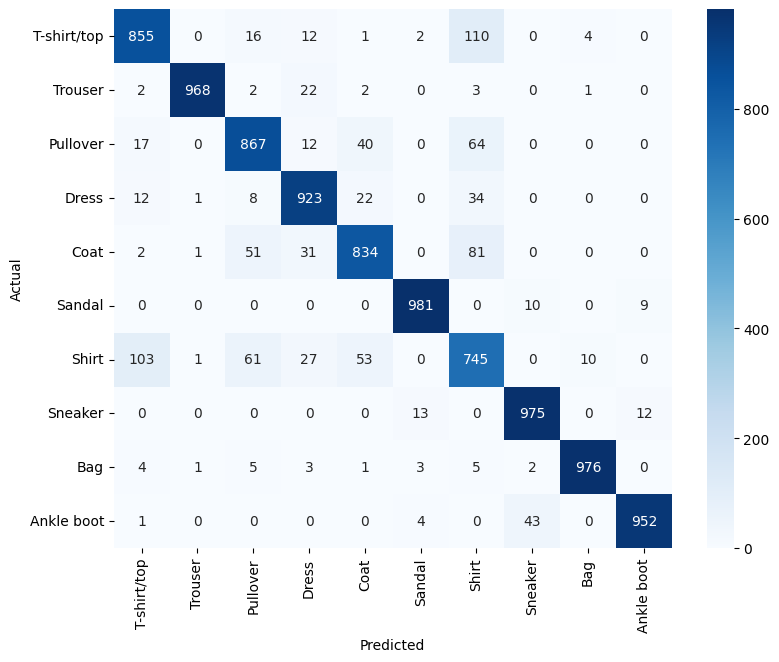

In [16]:
cm = confusion_matrix(y_test, y_pred_cnn)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

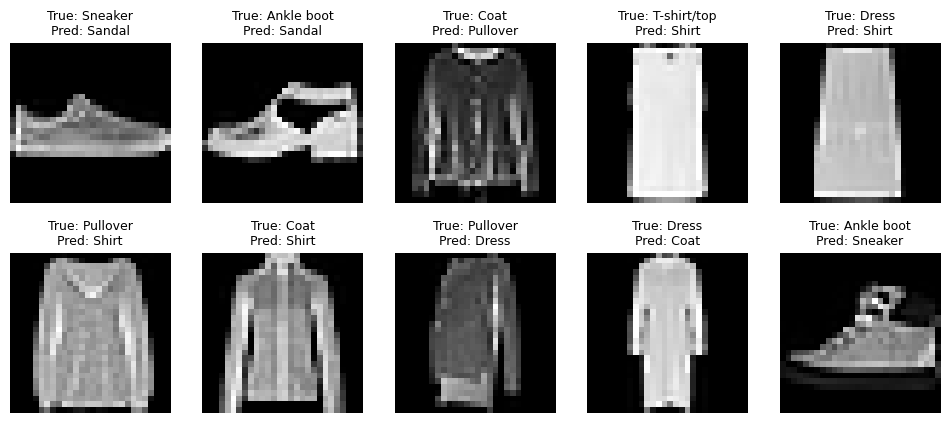

In [17]:
wrong = np.where(y_pred_cnn != y_test)[0]

plt.figure(figsize=(12, 5))
for i, idx in enumerate(wrong[:10]):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[idx].reshape(28, 28), cmap='gray')
    plt.title(f'True: {class_names[y_test[idx]]}\nPred: {class_names[y_pred_cnn[idx]]}', fontsize=9)
    plt.axis('off')
plt.show()

# ***ANN vs CNN***

In [18]:
y_pred_ann = np.argmax(ann_model.predict(X_test, verbose=0), axis=1)

results = []
for name, y_pred in [("ANN", y_pred_ann), ("CNN", y_pred_cnn)]:
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average='macro'),
        "Recall": recall_score(y_test, y_pred, average='macro'),
        "F1": f1_score(y_test, y_pred, average='macro')
    })

results_df = pd.DataFrame(results)
results_df

,Model,Accuracy,Precision,Recall,F1
0,ANN,0.8845,0.885067,0.8845,0.884525
1,CNN,0.9076,0.908690,0.9076,0.907981


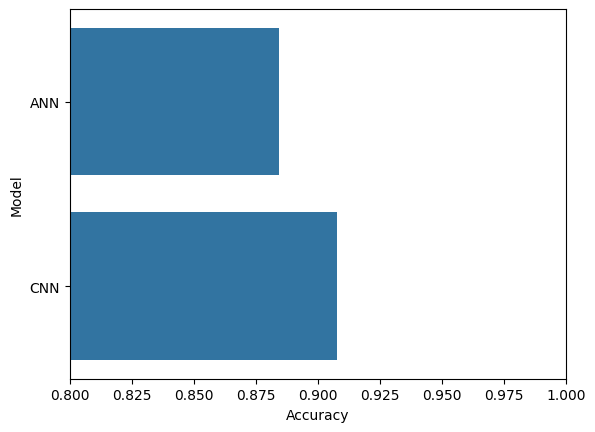

In [19]:
sns.barplot(x="Accuracy", y="Model", data=results_df)
plt.xlim(0.8, 1.0)
plt.show()